# 02 - Análisis: ¿el "buen precio" Spot fue realmente un buen negocio?

Este notebook parte de los archivos generados por `01_limpieza_datos.ipynb`.

**Pregunta:** una vez sumados el transporte, el costo de almacenamiento, la capacidad de bodega y el tiempo
que el material pasa guardado frente a su vida útil, ¿las compras Spot salen más baratas que las de contrato?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("graficos", exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

In [ ]:
# Parámetros
CASTIGO_VENCIMIENTO = 0.50   # % del precio que se pierde si el lote supera su vida útil
DIAS_PERIODO = 274           # días entre el 1 de enero y el 30 de septiembre de 2024

In [ ]:
datos = pd.read_excel("datos_limpios/compras_limpias.xlsx")
capacidad = pd.read_excel("datos_limpios/capacidad_centros.xlsx")

df = datos[datos["usar_en_analisis"]].copy()
df["BuyingMode"].value_counts()

Filas totales: 165
Filas para el análisis: 134


Contract    82
Spot        52
Name: BuyingMode, dtype: int64

## 2. Costo total por unidad (landed cost)

In [ ]:
df["transporte_unidad"] = df["TransportCostUSD"] / df["OrderQuantity"]
df["almacenamiento_unidad"] = df["StorageCostPerUnitPerDay"].fillna(0) * df["dias_almacenamiento"]
df["vencimiento_unidad"] = np.where(df["supera_vida_util"], CASTIGO_VENCIMIENTO * df["UnitPriceUSD"], 0)

df["costo_total_unidad"] = (df["UnitPriceUSD"] + df["transporte_unidad"]
                            + df["almacenamiento_unidad"] + df["vencimiento_unidad"])

df["pct_vida_util_usada"] = df["DaysInStorage"] / df["ShelfLifeDays"]

df[["POSampleID", "MaterialName", "BuyingMode", "UnitPriceUSD", "transporte_unidad",
    "almacenamiento_unidad", "vencimiento_unidad", "costo_total_unidad"]].head(10)

,POSampleID,MaterialName,BuyingMode,UnitPriceUSD,transporte_unidad,almacenamiento_unidad,vencimiento_unidad,costo_total_unidad
0,PO10001-P,Enzyme Complex,Contract,26.67,0.54,1.19,0.00,28.40
1,PO10002-P,Crude Palm Oil,Spot,24.99,1.00,4.84,12.49,43.32
2,PO10003-P,Yellow Corn,Contract,31.99,1.16,0.94,0.00,34.10
3,PO10004-P,Soy Oil,Spot,4.64,0.36,3.26,2.32,10.58
4,PO10005-S,Amino Acid Blend,Spot,6.54,0.48,9.21,3.27,19.50
5,PO10006-P,Inbound Freight - Truck,Contract,37.53,1.28,0.00,0.00,38.81
6,PO10007-N,Vitamin Premix,Contract,29.71,0.86,1.23,0.00,31.80
7,PO10008-P,Yellow Corn,Contract,33.20,0.71,1.38,0.00,35.29
8,PO10009-P,Gearbox Seal Kit,Contract,8.83,0.19,0.20,0.00,9.22
9,PO10010-P,Bearing Assembly,Contract,21.24,0.59,0.24,0.00,22.07


### Estructura de costos: ticket promedio categoría y modo de compra

In [ ]:
estructura = df.groupby(["Category", "BuyingMode"]).agg(
    ordenes=("POSampleID", "count"),
    precio=("UnitPriceUSD", "median"),
    transporte=("transporte_unidad", "median"),
    almacenamiento=("almacenamiento_unidad", "median"),
    vencimiento=("vencimiento_unidad", "median"),
    costo_total=("costo_total_unidad", "median"),
    dias_bodega=("DaysInStorage", "median"),
    lotes_vencidos=("supera_vida_util", "sum"),
)
estructura

ordenes  precio  transporte  almacenamiento  \
Category           BuyingMode                                                
Logistics Services Contract         10   34.99        0.90            0.00   
                   Spot             11   30.61        2.08            0.00   
MRO / Spare Parts  Contract         30   22.23        0.66            0.23   
                   Spot             10   16.75        0.87            0.84   
Packaging          Contract          8   15.25        0.49            0.21   
                   Spot             14   15.55        1.14            0.58   
Raw Materials      Contract         34   26.33        0.59            1.21   
                   Spot             17   15.00        0.89            5.35   

                               vencimiento  costo_total  dias_bodega  \
Category           BuyingMode                                          
Logistics Services Contract           0.00        35.89        19.00   
                   Spot               0.00        32.72       104.00   
MRO / Spare Parts  Contract           0.00        23.09        25.00   
                   Spot               0.00        18.87       107.50   
Packaging          Contract           0.00        15.98        27.50   
                   Spot               0.00        17.40       144.50   
Raw Materials      Contract           0.00        27.51        24.00   
                   Spot               3.44        19.50       116.00   

                               lotes_vencidos  
Category           BuyingMode                  
Logistics Services Contract                 0  
                   Spot                     0  
MRO / Spare Parts  Contract                 0  
                   Spot                     0  
Packaging          Contract                 0  
                   Spot                     0  
Raw Materials      Contract                 1  
                   Spot                    14

Primera lectura: en todas las categorías Spot tiene un **precio** menor, pero los lotes Spot se quedan en
bodega unas 4 veces más tiempo (~110 días contra ~25). En materias primas eso hace que el almacenamiento y el
vencimiento sean más caros que el descuento.

## 3. Comparación Spot vs. Contrato

**Línea base:** para cada material, la **mediana del costo total por unidad de sus compras por contrato**.
Es "lo que habría costado comprar ese material por el proceso normal".

Para cada compra Spot calculo:
- **Ahorro en precio** = precio contrato (mediana) − precio Spot → lo que ve el comprador
- **Ahorro real** = costo total contrato (mediana) − costo total Spot → lo que realmente se ahorró

In [ ]:
base_contrato = (df[df["BuyingMode"] == "Contract"]
                 .groupby("MaterialCode")
                 .agg(precio_contrato=("UnitPriceUSD", "median"),
                      costo_total_contrato=("costo_total_unidad", "median"))
                 .reset_index())

spot = df[df["BuyingMode"] == "Spot"].merge(base_contrato, on="MaterialCode", how="left")

# Algunos materiales solo se compraron en Spot: no tienen con qué compararse
print("Compras Spot sin línea base de contrato:")
print(spot[spot["costo_total_contrato"].isna()][["POSampleID", "MaterialName"]])
spot = spot[spot["costo_total_contrato"].notna()].copy()
print("\nCompras Spot comparables:", len(spot))

Compras Spot sin línea base de contrato:
   POSampleID        MaterialName
3   PO10011-N  PP Woven Bags 25kg
6   PO10018-P  Corrugated Cartons
25  PO10083-N  Corrugated Cartons
38  PO10131-P  PP Woven Bags 25kg

Compras Spot comparables: 48


In [ ]:
spot["ahorro_precio_unidad"] = spot["precio_contrato"] - spot["UnitPriceUSD"]
spot["ahorro_real_unidad"] = spot["costo_total_contrato"] - spot["costo_total_unidad"]

spot["ahorro_precio_usd"] = spot["ahorro_precio_unidad"] * spot["OrderQuantity"]
spot["ahorro_real_usd"] = spot["ahorro_real_unidad"] * spot["OrderQuantity"]

spot["ahorro_precio_pct"] = spot["ahorro_precio_unidad"] / spot["precio_contrato"]
spot["ahorro_real_pct"] = spot["ahorro_real_unidad"] / spot["costo_total_contrato"]

spot["buen_negocio"] = spot["ahorro_real_unidad"] > 0

### Resultado por categoría

In [ ]:
resumen = spot.groupby("Category").agg(
    compras_spot=("POSampleID", "count"),
    descuento_precio_mediana=("ahorro_precio_pct", "median"),
    ahorro_real_mediana=("ahorro_real_pct", "median"),
    ahorro_precio_usd=("ahorro_precio_usd", "sum"),
    ahorro_real_usd=("ahorro_real_usd", "sum"),
    buenos_negocios=("buen_negocio", "sum"),
    lotes_vencidos=("supera_vida_util", "sum"),
)
resumen.loc["TOTAL"] = [len(spot), spot["ahorro_precio_pct"].median(), spot["ahorro_real_pct"].median(),
                        spot["ahorro_precio_usd"].sum(), spot["ahorro_real_usd"].sum(),
                        spot["buen_negocio"].sum(), spot["supera_vida_util"].sum()]
resumen

,compras_spot,descuento_precio_mediana,ahorro_real_mediana,ahorro_precio_usd,ahorro_real_usd,buenos_negocios,lotes_vencidos
Category,,,,,,,
Logistics Services,11.00,0.12,0.08,"47,008.39","33,445.33",9.00,0.00
MRO / Spare Parts,10.00,0.18,0.13,"51,147.82","38,468.46",10.00,0.00
Packaging,10.00,0.13,0.07,"40,175.62","26,071.81",8.00,0.00
Raw Materials,17.00,0.18,-0.41,"65,695.29","-158,359.40",3.00,14.00
TOTAL,48.00,0.16,0.06,"204,027.11","-60,373.81",30.00,14.00


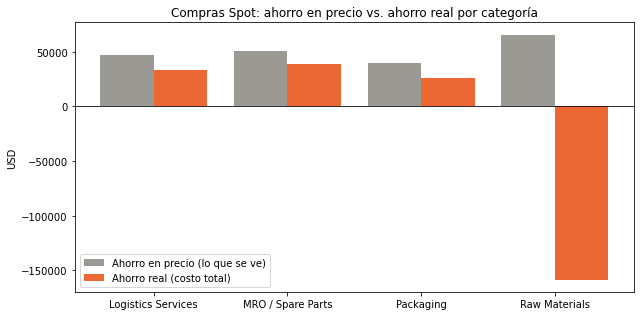

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(resumen) - 1)          # sin la fila TOTAL
r = resumen.drop("TOTAL")

ax.bar(x - 0.2, r["ahorro_precio_usd"], width=0.4, label="Ahorro en precio (lo que se ve)", color="#9a9994")
ax.bar(x + 0.2, r["ahorro_real_usd"], width=0.4, label="Ahorro real (costo total)", color="#eb6834")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(r.index)
ax.set_ylabel("USD")
ax.set_title("Compras Spot: ahorro en precio vs. ahorro real por categoría")
ax.legend()
plt.tight_layout()
plt.savefig("graficos/ahorro_por_categoria.png", dpi=150)
plt.show()

### ¿Influye cuánto de la vida útil se consumió en bodega?

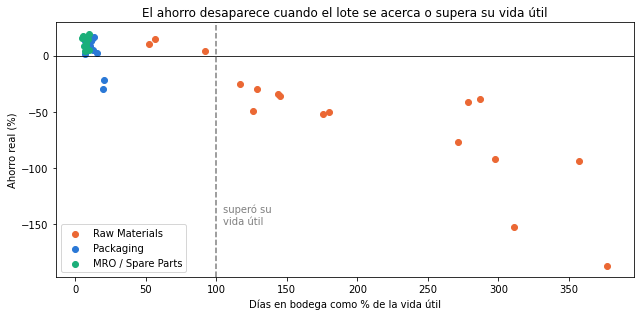

In [ ]:
fisicos = spot[~spot["es_servicio"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
for categoria, color in [("Raw Materials", "#eb6834"), ("Packaging", "#2a78d6"), ("MRO / Spare Parts", "#1baf7a")]:
    sub = fisicos[fisicos["Category"] == categoria]
    ax.scatter(sub["pct_vida_util_usada"] * 100, sub["ahorro_real_pct"] * 100, label=categoria, color=color)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(100, color="gray", linestyle="--")
ax.text(105, -150, "superó su\nvida útil", color="gray")
ax.set_xlabel("Días en bodega como % de la vida útil")
ax.set_ylabel("Ahorro real (%)")
ax.set_title("El ahorro desaparece cuando el lote se acerca o supera su vida útil")
ax.legend()
plt.tight_layout()
plt.savefig("graficos/vida_util_vs_ahorro.png", dpi=150)
plt.show()

### Ejemplo paso a paso: PO10041-S (Wheat Bran)

In [ ]:
ej = spot[spot["POSampleID"] == "PO10041-S"].iloc[0]

print("Cantidad:", ej["OrderQuantity"])
print(f"Precio Spot: {ej['UnitPriceUSD']:.2f}  vs  precio contrato (mediana): {ej['precio_contrato']:.2f}"
      f"  -> descuento {ej['ahorro_precio_pct']:.0%}")
print(f"Transporte por unidad: {ej['TransportCostUSD']:.2f} / {ej['OrderQuantity']} = {ej['transporte_unidad']:.2f}")
print(f"Almacenamiento: {ej['StorageCostPerUnitPerDay']} x {ej['DaysInStorage']:.0f} días = {ej['almacenamiento_unidad']:.2f}")
print(f"Vida útil: {ej['ShelfLifeDays']:.0f} días -> vencido, castigo 50% x {ej['UnitPriceUSD']:.2f} = {ej['vencimiento_unidad']:.2f}")
print(f"Costo total Spot: {ej['costo_total_unidad']:.2f}  vs  costo total contrato: {ej['costo_total_contrato']:.2f}")
print(f"Ahorro real: {ej['ahorro_real_unidad']:.2f} por unidad x {ej['OrderQuantity']} = {ej['ahorro_real_usd']:,.0f} USD")

Cantidad: 1875
Precio Spot: 4.10  vs  precio contrato (mediana): 5.04  -> descuento 19%
Transporte por unidad: 601.32 / 1875 = 0.32
Almacenamiento: 0.0579 x 137 días = 7.93
Vida útil: 44 días -> vencido, castigo 50% x 4.10 = 2.05
Costo total Spot: 14.40  vs  costo total contrato: 5.71
Ahorro real: -8.70 por unidad x 1875 = -16,305 USD


## 4. Punto de equilibrio: ¿cuántos días puede estar guardado un lote Spot?

Sin contar el vencimiento, el descuento se "gasta" en almacenamiento. Los días que puede estar guardado
antes de costar más que el contrato son:

```
días de equilibrio = (costo total contrato − precio Spot − transporte Spot) / costo de almacenamiento por día
```

In [ ]:
fisicos = spot[~spot["es_servicio"]].copy()
fisicos["dias_equilibrio"] = ((fisicos["costo_total_contrato"] - fisicos["UnitPriceUSD"]
                               - fisicos["transporte_unidad"]) / fisicos["StorageCostPerUnitPerDay"])

fisicos.groupby("Category").agg(
    dias_equilibrio=("dias_equilibrio", "median"),
    dias_reales=("DaysInStorage", "median"),
    vida_util=("ShelfLifeDays", "median"),
)

,dias_equilibrio,dias_reales,vida_util
Category,,,
MRO / Spare Parts,418.52,107.50,"1,386.50"
Packaging,387.76,144.50,"1,179.00"
Raw Materials,95.93,116.00,65.00


- **Materias primas:** el descuento alcanza para ~96 días de almacenamiento, pero la vida útil es de ~65 días.
  El límite real es el **vencimiento**, y los lotes Spot estuvieron guardados ~116 días.
- **Empaque y repuestos:** el descuento alcanza para ~400 días y los lotes estuvieron ~110-145. Hay margen.

## 5. Comprobación con el benchmark: ¿el precio Spot era realmente bajo?

In [ ]:
df["descuento_vs_referencia"] = 1 - df["UnitPriceUSD"] / df["precio_referencia"]
df.groupby(["Category", "BuyingMode"])["descuento_vs_referencia"].median().unstack()

BuyingMode,Contract,Spot
Category,,
Logistics Services,0.03,0.13
MRO / Spare Parts,-0.01,0.16
Packaging,0.01,0.15
Raw Materials,0.02,0.16


Sí: los precios Spot están entre 13% y 16% por debajo del precio de referencia y los de contrato muy cerca
(entre -1% y 3%). El precio bajo era real; el problema aparece después de la compra.

## 6. Capacidad de bodega

Supuesto: la capacidad es **compartida** entre todos los lotes que están en el centro al mismo tiempo.
Como aproximación simple uso las **unidades-día** (cantidad × días en bodega):

```
ocupación promedio = suma de unidades-día / días del periodo (274)
```

Solo tengo una muestra de órdenes, así que la ocupación real es mayor: esto es un **mínimo**.

In [ ]:
bodega = datos[(~datos["es_servicio"]) & (~datos["flag_fuera_de_fecha"]) & (datos["DaysInStorage"].notna())].copy()
bodega["unidades_dia"] = bodega["OrderQuantity"] * bodega["DaysInStorage"]

ocupacion = bodega[~bodega["flag_supera_capacidad"]].pivot_table(
    index="Center", columns="BuyingMode", values="unidades_dia", aggfunc="sum")
ocupacion["ocupacion_promedio"] = (ocupacion["Contract"] + ocupacion["Spot"]) / DIAS_PERIODO
ocupacion["pct_spot"] = ocupacion["Spot"] / (ocupacion["Contract"] + ocupacion["Spot"])
ocupacion = ocupacion.merge(capacidad.set_index("Center"), left_index=True, right_index=True)
ocupacion["pct_capacidad"] = ocupacion["ocupacion_promedio"] / ocupacion["StorageCapacityUnits"]
ocupacion

,Contract,Spot,ocupacion_promedio,pct_spot,CenterName,StorageCapacityUnits,pct_capacidad
Center,,,,,,,
N,"1,048,169.00","1,973,696.00","11,028.70",0.65,North Plant,60000,0.18
P,"840,677.00","2,203,399.00","11,109.77",0.72,Port Bonded Warehouse,18000,0.62
S,"774,442.00","3,434,034.00","15,359.40",0.82,South Plant,42000,0.37


In [ ]:
# Las 3 órdenes excluidas, frente a la capacidad de su centro
datos[datos["flag_supera_capacidad"]][["POSampleID", "MaterialName", "Center", "OrderQuantity", "StorageCapacityUnits"]]

,POSampleID,MaterialName,Center,OrderQuantity,StorageCapacityUnits
71,PO10072-P,Corrugated Cartons,P,19043,18000
138,PO10139-S,Amino Acid Blend,S,43496,42000
155,PO10156-N,Crude Palm Oil,N,60785,60000


- Las compras Spot ocupan entre el 65% y el 82% del espacio (unidades-día) en todos los centros, porque se
  quedan mucho más tiempo.
- La **Port Bonded Warehouse** es la más llena: en promedio usa al menos el 62% de su capacidad solo con las
  órdenes de la muestra. En los días de más compras seguramente se llena.
- Las 3 órdenes excluidas no caben en su bodega ni estando vacía: o son errores de datos o generaron un costo
  de capacidad extra (bodega externa) que no aparece en los datos.

## 7. Sensibilidad: ¿la conclusión cambia si cambian los supuestos?

Recalculo el ahorro real por categoría cambiando:
- el castigo por vencimiento (0%, 25%, 50%, 100%)
- el costo de almacenamiento (100% o 50% de la tarifa dada, por si la tarifa está sobreestimada)

In [ ]:
resultados = []

for castigo in [0, 0.25, 0.50, 1.0]:
    for factor_almacenamiento in [1.0, 0.5]:
        temp = df.copy()
        temp["costo"] = (temp["UnitPriceUSD"] + temp["transporte_unidad"]
                         + temp["almacenamiento_unidad"] * factor_almacenamiento
                         + np.where(temp["supera_vida_util"], castigo * temp["UnitPriceUSD"], 0))

        base = temp[temp["BuyingMode"] == "Contract"].groupby("MaterialCode")["costo"].median().rename("costo_contrato")
        s = temp[temp["BuyingMode"] == "Spot"].merge(base, on="MaterialCode")
        s["ahorro_usd"] = (s["costo_contrato"] - s["costo"]) * s["OrderQuantity"]

        por_cat = s.groupby("Category")["ahorro_usd"].sum()
        por_cat["castigo_vencimiento"] = castigo
        por_cat["factor_almacenamiento"] = factor_almacenamiento
        resultados.append(por_cat)

sensibilidad = pd.DataFrame(resultados).set_index(["castigo_vencimiento", "factor_almacenamiento"])
sensibilidad

Category                                   Logistics Services  \
castigo_vencimiento factor_almacenamiento                       
0.00                1.00                            33,445.33   
                    0.50                            33,445.33   
0.25                1.00                            33,445.33   
                    0.50                            33,445.33   
0.50                1.00                            33,445.33   
                    0.50                            33,445.33   
1.00                1.00                            33,445.33   
                    0.50                            33,445.33   

Category                                   MRO / Spare Parts  Packaging  \
castigo_vencimiento factor_almacenamiento                                 
0.00                1.00                           38,468.46  26,071.81   
                    0.50                           43,114.32  29,769.79   
0.25                1.00                           38,468.46  26,071.81   
                    0.50                           43,114.32  29,769.79   
0.50                1.00                           38,468.46  26,071.81   
                    0.50                           43,114.32  29,769.79   
1.00                1.00                           38,468.46  26,071.81   
                    0.50                           43,114.32  29,769.79   

Category                                   Raw Materials  
castigo_vencimiento factor_almacenamiento                 
0.00                1.00                      -44,392.58  
                    0.50                        6,386.76  
0.25                1.00                     -101,375.99  
                    0.50                      -50,031.43  
0.50                1.00                     -158,359.40  
                    0.50                     -107,014.84  
1.00                1.00                     -272,326.22  
                    0.50                     -220,981.66

En empaque, repuestos y servicios el ahorro es positivo en todos los escenarios. En materias primas solo deja de
ser negativo si **a la vez** no hay castigo por vencimiento y la tarifa de almacenamiento es la mitad de la dada.

In [ ]:
# ¿Y si se incluyen las 3 órdenes que superan la capacidad? (solo materias primas y empaque)
incluidas = datos[datos["flag_supera_capacidad"]].copy()
incluidas["costo_total_unidad"] = (incluidas["UnitPriceUSD"]
                                   + incluidas["TransportCostUSD"] / incluidas["OrderQuantity"]
                                   + incluidas["StorageCostPerUnitPerDay"] * incluidas["DaysInStorage"]
                                   + np.where(incluidas["supera_vida_util"], CASTIGO_VENCIMIENTO * incluidas["UnitPriceUSD"], 0))
incluidas = incluidas.merge(base_contrato, on="MaterialCode", how="left")
incluidas["ahorro_real_usd"] = (incluidas["costo_total_contrato"] - incluidas["costo_total_unidad"]) * incluidas["OrderQuantity"]
incluidas[["POSampleID", "MaterialName", "OrderQuantity", "costo_total_unidad", "costo_total_contrato", "ahorro_real_usd"]]

,POSampleID,MaterialName,OrderQuantity,costo_total_unidad,costo_total_contrato,ahorro_real_usd
0,PO10072-P,Corrugated Cartons,19043,7.06,NaN,NaN
1,PO10139-S,Amino Acid Blend,43496,17.08,10.05,"-305,419.79"
2,PO10156-N,Crude Palm Oil,60785,46.88,33.34,"-822,973.97"


## 8. Conclusiones

**1. Spot en materias primas perecederas no fue un buen negocio.**
El descuento en precio fue de 18% (mediana), pero el costo total salió 41% más caro que comprar por contrato.
En dinero, un ahorro aparente de +65.700 USD terminó en **-158.400 USD** (17 compras). 14 de 17 lotes superaron
su vida útil. Las únicas 3 compras rentables son justamente las 3 que se usaron antes de vencerse.
Aunque el vencimiento no costara nada (castigo 0%), el resultado sigue siendo negativo (-44.400 USD).

**2. Spot en materiales duraderos (empaque y repuestos) sí funcionó.**
18 de 20 compras tuvieron ahorro real (+64.500 USD de +91.300 USD en precio, se conserva ~70% del descuento).
Su vida útil es de años y el costo de almacenarlos es bajo, así que el descuento aguanta ~400 días en bodega.

**Regla práctica:** comprar Spot solo si
`descuento por unidad > transporte extra por unidad + costo de almacenamiento diario × días esperados de consumo`
**y** si los días esperados de consumo son bastante menores que la vida útil.

**Lo que más limita la confianza:**
- Las tarifas de almacenamiento de materias primas parecen muy altas (Wheat Bran: ~1,2% de su valor por día).
  La conclusión 1 depende de ellas: con la mitad de la tarifa y sin castigo, materias primas queda en +6.400 USD.
- Muestra pequeña (17 compras Spot de materias primas) y sin fechas reales de recepción y consumo.
- La línea base junta todos los centros porque hay pocas compras por contrato por centro.